In [1]:
import random
import re
from urllib.parse import urlparse

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestClassifier
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (ConfusionMatrixDisplay, accuracy_score,
                             classification_report, confusion_matrix, f1_score)
from sklearn.model_selection import cross_val_score, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import FunctionTransformer, StandardScaler

RANDOM_STATE = 42
LABELS = {0: "Safe", 1: "Phishing"}

URL_RE = re.compile(r"(?:https?://|www\.)[^\s<>\"')]+", re.IGNORECASE)
IP_HOST_RE = re.compile(r"^\d{1,3}(?:\.\d{1,3}){3}$")
SHORTENERS = {"bit.ly", "tinyurl.com", "goo.gl", "t.co", "ow.ly", "is.gd", "buff.ly", "cutt.ly", "rb.gy"}
SUSPICIOUS_TLDS = {"xyz", "top", "click", "support", "live", "icu", "tk", "ml", "ga", "cf", "gq", "work", "zip"}
URGENCY_WORDS = ["urgent", "immediately", "suspended", "verify", "confirm", "limited time", "act now",
                 "expires", "within 24 hours", "final notice", "locked", "unusual activity", "alert"]
CREDENTIAL_WORDS = ["password", "login", "log in", "sign in", "account", "bank", "ssn", "pin", "otp",
                    "credit card", "update your", "billing"]
MONEY_WORDS = ["winner", "prize", "lottery", "reward", "refund", "gift card", "free", "cash", "claim", "$", "rs."]

FEATURE_NAMES = ["n_urls", "has_ip_url", "has_at_in_url", "has_shortener", "has_bad_tld", "n_http_only",
                 "max_url_len", "max_subdomains", "has_punycode_or_hyphens", "urgency_hits",
                 "credential_hits", "money_hits", "n_exclaim", "upper_ratio", "digit_ratio", "text_len"]


# ---------------------- Feature engineering ----------------------
def extract_urls(text):
    return [u.rstrip(".,;") for u in URL_RE.findall(text)]


def host_of(url):
    if not url.lower().startswith("http"):
        url = "http://" + url
    return (urlparse(url).hostname or "").lower()


def handcrafted_features(text):
    text = str(text)
    low = text.lower()
    urls = extract_urls(text)
    hosts = [host_of(u) for u in urls]
    n = max(len(text), 1)
    return [
        len(urls),
        int(any(IP_HOST_RE.match(h) for h in hosts)),
        int(any("@" in u for u in urls)),
        int(any(h in SHORTENERS for h in hosts)),
        int(any(h.rsplit(".", 1)[-1] in SUSPICIOUS_TLDS for h in hosts if "." in h)),
        sum(u.lower().startswith("http://") for u in urls),
        max((len(u) for u in urls), default=0),
        max((h.count(".") - 1 for h in hosts), default=0),
        int(any("xn--" in h or h.count("-") >= 2 for h in hosts)),
        sum(w in low for w in URGENCY_WORDS),
        sum(w in low for w in CREDENTIAL_WORDS),
        sum(w in low for w in MONEY_WORDS),
        text.count("!"),
        sum(c.isupper() for c in text) / n,
        sum(c.isdigit() for c in text) / n,
        len(text),
    ]


def features_matrix(series):
    return np.array([handcrafted_features(t) for t in series], dtype=float)


def explain_email(text):
    """Human-readable red flags found in an email."""
    f = dict(zip(FEATURE_NAMES, handcrafted_features(text)))
    flags = []
    if f["has_ip_url"]:
        flags.append("Link uses a raw IP address instead of a domain name")
    if f["has_at_in_url"]:
        flags.append("Link contains '@' (used to hide the real destination)")
    if f["has_shortener"]:
        flags.append("Link uses a URL shortener that hides the real site")
    if f["has_bad_tld"]:
        flags.append("Link uses a domain extension often abused by scammers")
    if f["n_http_only"]:
        flags.append(f"{int(f['n_http_only'])} link(s) use insecure HTTP instead of HTTPS")
    if f["max_subdomains"] >= 3:
        flags.append("Link has many subdomains (e.g. bank.com.secure.fake.site)")
    if f["has_punycode_or_hyphens"]:
        flags.append("Link domain has suspicious hyphens or punycode")
    if f["urgency_hits"] >= 2:
        flags.append(f"Urgent or threatening language ({int(f['urgency_hits'])} trigger words)")
    if f["credential_hits"] >= 2 and f["n_urls"]:
        flags.append("Asks you to log in or update account details through a link")
    if f["money_hits"] >= 2:
        flags.append("Offers money, prizes or refunds")
    if f["n_exclaim"] >= 3:
        flags.append("Excessive exclamation marks")
    return flags


# ---------------------- Dataset loading ----------------------
TEXT_COLS = ["text", "email", "email text", "body", "message", "content", "email_text"]
LABEL_COLS = ["label", "email type", "class", "target", "category", "spam", "type"]
PHISH_VALUES = {"phishing", "phishing email", "phish", "spam", "1", "malicious", "fraud", "unsafe"}
SAFE_VALUES = {"safe", "safe email", "legitimate", "legit", "ham", "0", "benign", "not spam", "normal"}


def load_dataset(path=None, n_per_class=1000):
    if path is None:
        print("[i] No CSV given: using built-in SYNTHETIC demo data.")
        return make_synthetic_dataset(n_per_class)
    df = pd.read_csv(path)
    cols = {c.lower().strip(): c for c in df.columns}
    text_col = next((cols[c] for c in TEXT_COLS if c in cols), None)
    label_col = next((cols[c] for c in LABEL_COLS if c in cols), None)
    if text_col is None or label_col is None:
        raise ValueError(f"Could not find text/label columns in {list(df.columns)}")

    def to_label(v):
        s = str(v).strip().lower()
        if s in PHISH_VALUES:
            return 1
        if s in SAFE_VALUES:
            return 0
        return None

    out = pd.DataFrame({"text": df[text_col].astype(str), "label": df[label_col].map(to_label)})
    out = out.dropna().drop_duplicates(subset="text")
    out["label"] = out["label"].astype(int)
    print(f"[i] Loaded {len(out)} emails from {path} "
          f"({out['label'].sum()} phishing / {(out['label'] == 0).sum()} safe)")
    return out.reset_index(drop=True)


def make_synthetic_dataset(n_per_class=1000, seed=RANDOM_STATE):
    rnd = random.Random(seed)
    brands = ["PayPal", "Amazon", "Netflix", "SBI Bank", "HDFC Bank", "Microsoft", "Google", "Apple",
              "Flipkart", "Paytm", "Instagram", "LinkedIn"]
    names = ["Alex", "Priya", "Rahul", "Sneha", "Arjun", "Meera", "John", "Anita", "Sam", "Riya"]
    good_domains = ["google.com", "amazon.in", "github.com", "linkedin.com", "microsoft.com", "makaut.ac.in",
                    "coursera.org", "zoom.us", "notion.so", "medium.com"]
    bad_hosts = ["secure-{b}-login.xyz", "{b}.verify-account.top", "update-{b}.support", "192.168.{x}.{y}",
                 "{b}-billing.click", "login.{b}.com.account-check.live", "xn--{b}-support.icu"]
    shorteners = ["bit.ly/{r}", "tinyurl.com/{r}", "cutt.ly/{r}"]

    def rid():
        return "".join(rnd.choices("abcdefghijklmnopqrstuvwxyz0123456789", k=7))

    def bad_url(b):
        b = b.lower().replace(" ", "")
        if rnd.random() < 0.25:
            return "http://" + rnd.choice(shorteners).format(r=rid())
        host = rnd.choice(bad_hosts).format(b=b, x=rnd.randint(1, 250), y=rnd.randint(1, 250))
        return rnd.choice(["http://", "https://"]) + host + "/" + rnd.choice(["login", "verify", "secure", "update"]) + "?id=" + rid()

    def good_url():
        return "https://www." + rnd.choice(good_domains) + "/" + rnd.choice(["", "help", "docs", "events", "account/settings"])

    phish_t = [
        "Dear customer, your {b} account has been suspended due to unusual activity. Verify your password immediately at {u} or it will be locked within 24 hours.",
        "URGENT: We could not process your payment. Update your billing details now: {u}. Failure to act will result in account closure.",
        "Congratulations {n}! You are the winner of a {b} gift card worth $500. Claim your prize here {u} before it expires!!!",
        "Security alert: someone tried to sign in to your {b} account. Confirm your identity and password at {u}.",
        "Final notice: your {b} refund of $249.99 is pending. Click {u} and enter your card details to receive the cash.",
        "Hello {n}, your mailbox is almost full. Log in at {u} to keep your account active, otherwise it will be deleted.",
        "Your {b} package could not be delivered. Pay the small fee of $1.99 via {u} to reschedule delivery.",
        "Dear {n}, we noticed a login from a new device. If this was not you, verify your account now {u}",
        "IT Helpdesk: password expires today. Keep your current password by signing in here: {u}",
        "Invoice attached for your recent purchase of $899. If you did not authorise it, cancel at {u} immediately.",
    ]
    phish_soft = [
        "Hi {n}, please review the shared document when you get a chance: {u}",
        "Hello {n}, your {b} subscription renewal is ready. Details here {u}",
        "Hi, can you check this updated schedule for me? {u} Thanks, {n}",
    ]
    safe_t = [
        "Hi {n}, attaching the notes from today's class. The assignment is due next Friday. Details are on {u} if you need them.",
        "Your {b} receipt for order #{o}. Thank you for shopping with us. You can view your order at {u}.",
        "Hello team, the meeting is moved to 3 PM tomorrow. Please confirm your attendance by replying to this email.",
        "Reminder: your library book is due on Monday. You can renew it online at {u}.",
        "Hi {n}, great catching up yesterday! Let's plan the project demo this weekend. Send me your slides when ready.",
        "Weekly newsletter: top 5 articles on machine learning this week. Read more at {u}. Unsubscribe anytime.",
        "Your password was changed successfully. If you did not make this change, contact support through the official {b} app.",
        "Hello {n}, your internship certificate has been issued. You can download it from {u}.",
        "Thanks for registering for the workshop on cloud computing. The session link will be shared an hour before at {u}.",
        "Hi, quick update: the exam timetable is out. Please check the college portal at {u} and let me know if you see any clash!",
    ]
    safe_urgent = [
        "Urgent: the lab session is cancelled today due to maintenance. Please check {u} for the new schedule.",
        "Important notice: your {b} account statement for this month is available. Sign in at {u} to view it.",
        "Action required: please confirm your seminar registration by Friday at {u}.",
    ]

    rows = []
    for _ in range(n_per_class):
        b, n = rnd.choice(brands), rnd.choice(names)
        tpl = rnd.choice(phish_soft) if rnd.random() < 0.2 else rnd.choice(phish_t)
        rows.append((tpl.format(b=b, n=n, u=bad_url(b)), 1))
        b, n = rnd.choice(brands), rnd.choice(names)
        tpl = rnd.choice(safe_urgent) if rnd.random() < 0.2 else rnd.choice(safe_t)
        text = tpl.format(b=b, n=n, u=good_url(), o=rnd.randint(10000, 99999))
        rows.append((text, 0))
    df = pd.DataFrame(rows, columns=["text", "label"]).drop_duplicates("text")
    return df.sample(frac=1, random_state=seed).reset_index(drop=True)


# ---------------------- Model + evaluation ----------------------
def build_pipeline(classifier):
    features = ColumnTransformer([
        ("tfidf", TfidfVectorizer(lowercase=True, stop_words="english", ngram_range=(1, 2),
                                  min_df=2, max_features=20000, sublinear_tf=True), "text"),
        ("handcrafted", Pipeline([("extract", FunctionTransformer(features_matrix)),
                                  ("scale", StandardScaler(with_mean=False))]), "text"),
    ])
    return Pipeline([("features", features), ("clf", classifier)])


def train_and_evaluate(df, test_size=0.2, show_plot=True):
    X_train, X_test, y_train, y_test = train_test_split(
        df[["text"]], df["label"], test_size=test_size, stratify=df["label"], random_state=RANDOM_STATE)
    print(f"[i] Train: {len(X_train)} emails | Test: {len(X_test)} emails\n")

    candidates = {
        "Logistic Regression": LogisticRegression(max_iter=1000, class_weight="balanced"),
        "Random Forest": RandomForestClassifier(n_estimators=200, random_state=RANDOM_STATE,
                                                n_jobs=-1, class_weight="balanced"),
    }
    results = {}
    for name, clf in candidates.items():
        model = build_pipeline(clf).fit(X_train, y_train)
        pred = model.predict(X_test)
        results[name] = {"model": model, "pred": pred,
                         "acc": accuracy_score(y_test, pred), "f1": f1_score(y_test, pred)}
        print(f"{name:20} accuracy = {results[name]['acc']:.4f}   F1 = {results[name]['f1']:.4f}")

    best_name = max(results, key=lambda k: (results[k]["f1"], results[k]["acc"]))
    best = results[best_name]
    print(f"\n>>> Best model: {best_name}")
    print(f"\nTest accuracy: {best['acc'] * 100:.2f}%\n")
    print(classification_report(y_test, best["pred"], target_names=["Safe", "Phishing"], digits=4))

    cm = confusion_matrix(y_test, best["pred"])
    tn, fp, fn, tp = cm.ravel()
    print(f"Confusion matrix -> True Safe: {tn} | False Phishing alarms: {fp} | "
          f"Missed phishing: {fn} | Caught phishing: {tp}")

    cv = cross_val_score(build_pipeline(candidates[best_name]), df[["text"]], df["label"],
                         cv=5, scoring="accuracy")
    print(f"5-fold cross-validation accuracy: {cv.mean() * 100:.2f}% (+/- {cv.std() * 100:.2f}%)")

    if show_plot:
        fig, ax = plt.subplots(figsize=(5, 4))
        ConfusionMatrixDisplay(cm, display_labels=["Safe", "Phishing"]).plot(ax=ax, cmap="Blues", colorbar=False)
        ax.set_title(f"Confusion Matrix - {best_name}\nAccuracy {best['acc'] * 100:.2f}%")
        plt.tight_layout()
        plt.savefig("confusion_matrix.png", dpi=150)
        plt.show()
    return best["model"], best_name, results


def predict_email(model, text, verbose=True):
    """Classify one email; returns (label, phishing_probability, red_flags)."""
    proba = float(model.predict_proba(pd.DataFrame({"text": [text]}))[0][1])
    label = LABELS[int(proba >= 0.5)]
    flags = explain_email(text)
    if verbose:
        print("-" * 60)
        print(f"Email     : {text[:110]}{'...' if len(text) > 110 else ''}")
        print(f"Verdict   : {label.upper()}  (phishing probability {proba * 100:.1f}%)")
        if flags:
            print("Red flags :")
            for f in flags:
                print("   -", f)
        else:
            print("Red flags : none detected")
    return label, proba, flags


def save_model(model, path="phishing_model.joblib"):
    import joblib
    joblib.dump(model, path)
    print(f"[+] Model saved to {path}")

[i] No CSV given: using built-in SYNTHETIC demo data.
[i] Train: 1245 emails | Test: 312 emails

Logistic Regression  accuracy = 1.0000   F1 = 1.0000
Random Forest        accuracy = 1.0000   F1 = 1.0000

>>> Best model: Logistic Regression

Test accuracy: 100.00%

              precision    recall  f1-score   support

        Safe     1.0000    1.0000    1.0000       112
    Phishing     1.0000    1.0000    1.0000       200

    accuracy                         1.0000       312
   macro avg     1.0000    1.0000    1.0000       312
weighted avg     1.0000    1.0000    1.0000       312

Confusion matrix -> True Safe: 112 | False Phishing alarms: 0 | Missed phishing: 0 | Caught phishing: 200
5-fold cross-validation accuracy: 100.00% (+/- 0.00%)


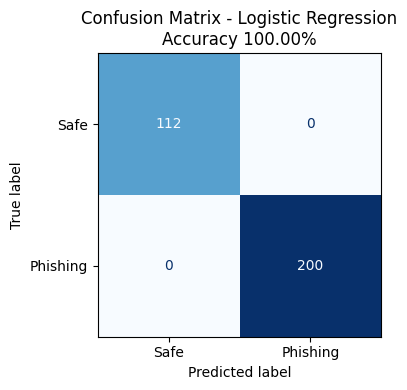

In [2]:
df = load_dataset()
model, best_name, results = train_and_evaluate(df)

[i] Loaded 100 emails from Phishing_validation_emails.csv (23 phishing / 77 safe)
[i] Train: 80 emails | Test: 20 emails

Logistic Regression  accuracy = 1.0000   F1 = 1.0000
Random Forest        accuracy = 1.0000   F1 = 1.0000

>>> Best model: Logistic Regression

Test accuracy: 100.00%

              precision    recall  f1-score   support

        Safe     1.0000    1.0000    1.0000        15
    Phishing     1.0000    1.0000    1.0000         5

    accuracy                         1.0000        20
   macro avg     1.0000    1.0000    1.0000        20
weighted avg     1.0000    1.0000    1.0000        20

Confusion matrix -> True Safe: 15 | False Phishing alarms: 0 | Missed phishing: 0 | Caught phishing: 5
5-fold cross-validation accuracy: 97.00% (+/- 2.45%)


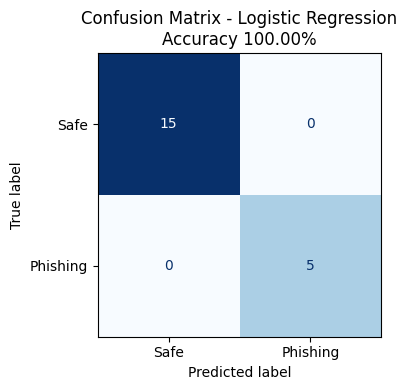

In [4]:
import urllib.request

url = "https://zenodo.org/records/13474746/files/Phishing_validation_emails.csv?download=1"
csv_path = "Phishing_validation_emails.csv"
urllib.request.urlretrieve(url, csv_path)

df = load_dataset(csv_path)
model, best_name, results = train_and_evaluate(df)

In [5]:
tests = [
    "URGENT: Your SBI Bank account is suspended. Verify your password now at http://192.168.4.7/login?id=x9 or it will be locked within 24 hours!!!",
    "Hi Priya, the meeting is moved to 3 PM tomorrow. Slides are on https://www.github.com/docs. Thanks!",
    "Congratulations! You won a $500 gift card. Claim: http://bit.ly/abc123",
    "Your internship certificate is ready, download it from https://www.coursera.org/account/settings",
]
for t in tests:
    predict_email(model, t)

# Try your own email:
my_email = input("Paste an email to check: ")
predict_email(model, my_email)

------------------------------------------------------------
Email     : URGENT: Your SBI Bank account is suspended. Verify your password now at http://192.168.4.7/login?id=x9 or it w...
Verdict   : PHISHING  (phishing probability 100.0%)
Red flags :
   - Link uses a raw IP address instead of a domain name
   - 1 link(s) use insecure HTTP instead of HTTPS
   - Urgent or threatening language (5 trigger words)
   - Asks you to log in or update account details through a link
   - Excessive exclamation marks
------------------------------------------------------------
Email     : Hi Priya, the meeting is moved to 3 PM tomorrow. Slides are on https://www.github.com/docs. Thanks!
Verdict   : SAFE  (phishing probability 0.1%)
Red flags : none detected
------------------------------------------------------------
Email     : Congratulations! You won a $500 gift card. Claim: http://bit.ly/abc123
Verdict   : PHISHING  (phishing probability 99.7%)
Red flags :
   - Link uses a URL shortener that hi

('Phishing', 0.9999999999987528, [])

In [6]:
from google.colab import files
save_model(model)
files.download("phishing_model.joblib")
files.download("confusion_matrix.png")

[+] Model saved to phishing_model.joblib


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>